# EDA: Cell Line Data

- **Purpose:** Inspect cell line QC, cell line and pool composition, and the unintegrated cell line UMAP.
- **Inputs:** `data/processed/preprocessed_cell_line.h5ad`.
- **Outputs:** `figures/EDA/EDA_cl_{qc,qc_histograms,composition,umap}.png`.
- **Result:** The UMAP shows the cell line structure before integration; QC and composition are summarized by sequencing pool.


Unintegrated look at `preprocessed_cell_line.h5ad`: QC metrics, composition, and PCA/UMAP built on 5,000 HVGs selected from the counts without a batch key.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
FIGS = ROOT / "figures" / "EDA"
FIGS.mkdir(parents=True, exist_ok=True)

sc.settings.verbosity = 1
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12})


warnings.filterwarnings(
    "ignore",
    message="constrained_layout not applied because axes sizes collapsed to zero",
)

# QC Metrics

In [2]:
adata = ad.read_h5ad(DATA / "preprocessed_cell_line.h5ad")
adata.var["mt"] = adata.var["gene_symbol"].str.startswith(("MT-", "mt-"))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata.shape

(2162, 28617)

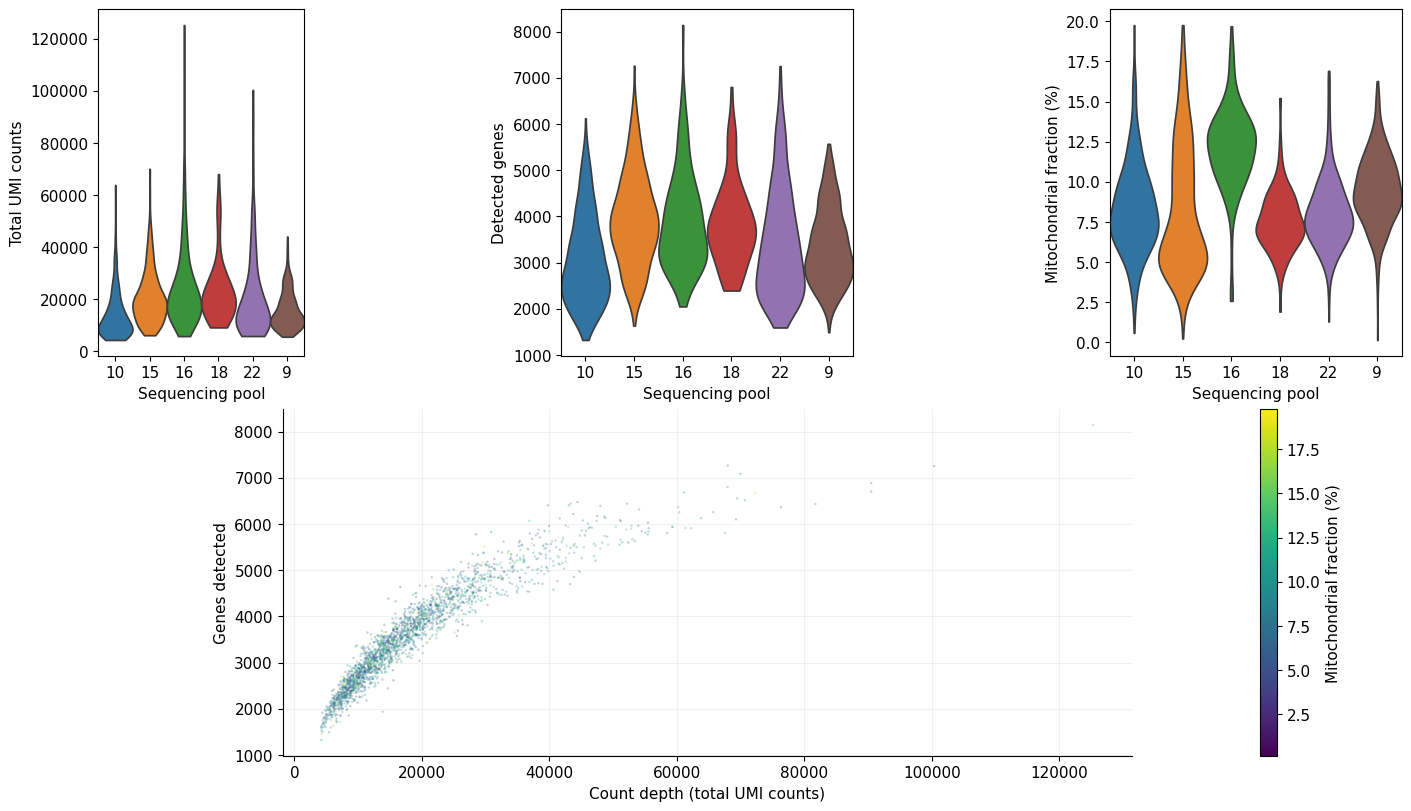

In [3]:
qc_labels = ["Total UMI counts", "Detected genes", "Mitochondrial fraction (%)"]

fig = plt.figure(figsize=(14, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 6)
ax_violins = [fig.add_subplot(gs[0, 2 * i:2 * i + 2]) for i in range(3)]
ax_depth = fig.add_subplot(gs[1, 1:5])

for ax, key, lab in zip(ax_violins, ["total_counts", "n_genes_by_counts", "pct_counts_mt"], qc_labels):
    sc.pl.violin(adata, key, groupby="pool_id", ax=ax, show=False, width=1.0, stripplot=False)
    ax.set_ylabel(lab)
    ax.set_xlabel("Sequencing pool")

counts = adata.obs["total_counts"].to_numpy()
genes = adata.obs["n_genes_by_counts"].to_numpy()
mito = adata.obs["pct_counts_mt"].to_numpy()

order = np.random.default_rng(0).permutation(len(counts))
pts = ax_depth.scatter(counts[order], genes[order], c=mito[order], s=3, alpha=0.3, linewidths=0, cmap="viridis")
ax_depth.set(xlabel="Count depth (total UMI counts)", ylabel="Genes detected")
ax_depth.spines[["top", "right"]].set_visible(False)
ax_depth.grid(alpha=0.25, linewidth=0.5)
cbar = fig.colorbar(pts, ax=ax_depth, label="Mitochondrial fraction (%)")
cbar.solids.set(alpha=1.0)

plt.savefig(FIGS / "EDA_cl_qc.png", dpi=200, bbox_inches="tight")

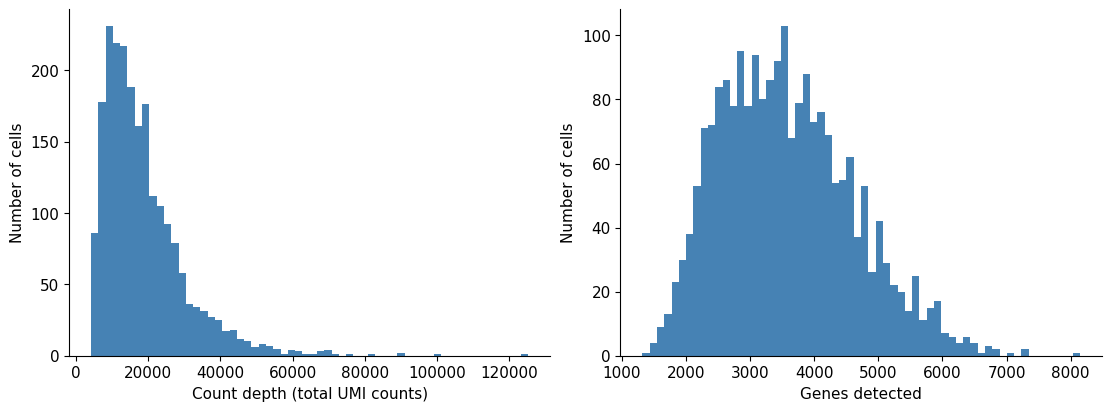

In [4]:
counts = adata.obs["total_counts"].to_numpy()
genes = adata.obs["n_genes_by_counts"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].hist(counts, bins=60, color="steelblue")
axes[0].set(xlabel="Count depth (total UMI counts)", ylabel="Number of cells")
axes[1].hist(genes, bins=60, color="steelblue")
axes[1].set(xlabel="Genes detected", ylabel="Number of cells")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.savefig(FIGS / "EDA_cl_qc_histograms.png", dpi=200, bbox_inches="tight")

# Dataset Composition

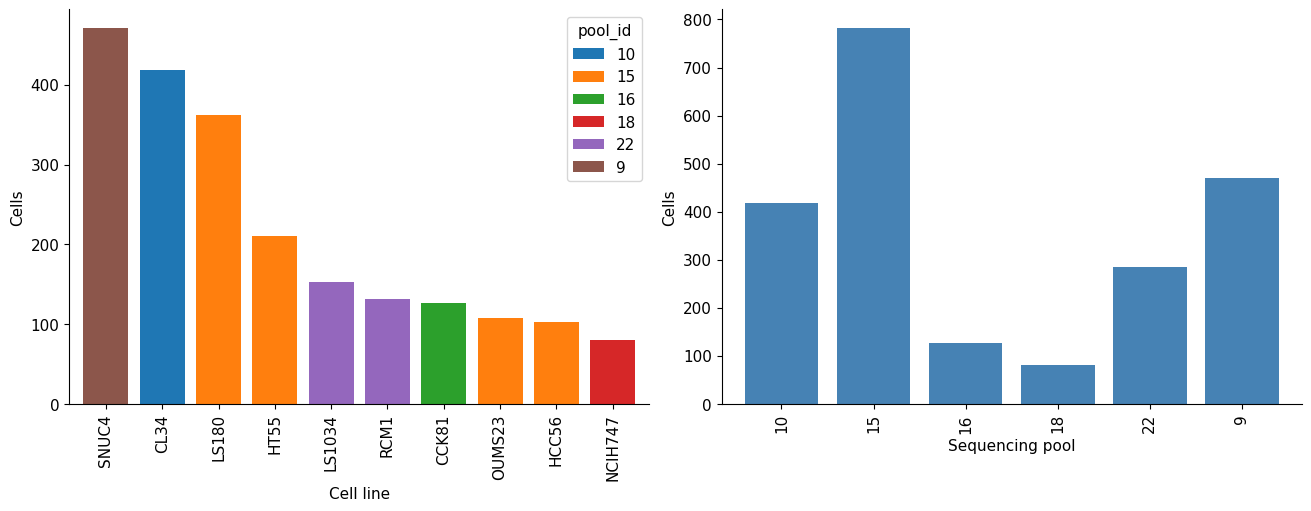

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

per_line = adata.obs.groupby(["cell_line", "pool_id"], observed=True).size().unstack(fill_value=0)
per_line.loc[per_line.sum(axis=1).sort_values(ascending=False).index].plot.bar(ax=axes[0], stacked=True, width=0.8)
axes[0].set(xlabel="Cell line", ylabel="Cells")

per_pool = adata.obs["pool_id"].value_counts().sort_index()
per_pool.plot.bar(ax=axes[1], color="steelblue", width=0.8)
axes[1].set(xlabel="Sequencing pool", ylabel="Cells")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.savefig(FIGS / "EDA_cl_composition.png", dpi=200, bbox_inches="tight")

# Unintegrated PCA UMAP

In [6]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000, flavor="seurat_v3")
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

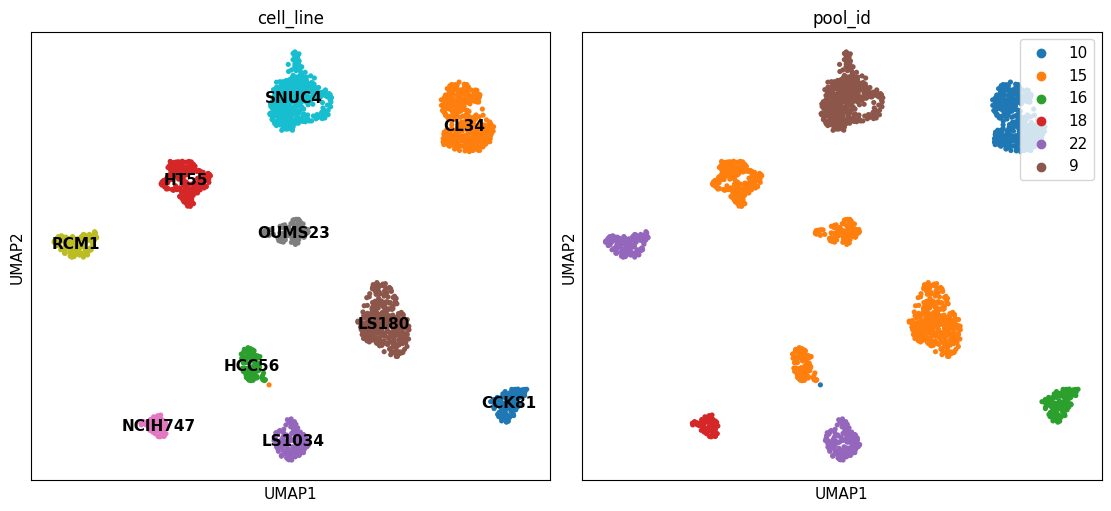

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
rng = np.random.default_rng(0)
adata = adata[rng.permutation(adata.n_obs)].copy()
sc.pl.umap(adata, color="cell_line", ax=axes[0], show=False, legend_loc="on data")
sc.pl.umap(adata, color="pool_id", ax=axes[1], show=False, legend_loc="upper right")
axes[1].get_legend().set_frame_on(True)
for ax in axes:
    ax.set(xlabel="UMAP1", ylabel="UMAP2")

plt.savefig(FIGS / "EDA_cl_umap.png", dpi=200, bbox_inches="tight")

# Metrics

In [8]:
obs = adata.obs

print("Cell line EDA metrics")
print()

per_line = obs.groupby("cell_line", observed=True).size()
print("cells per cell line:")
print(per_line)
print(f"cells per line: min {per_line.min()} ({per_line.idxmin()}), max {per_line.max()} ({per_line.idxmax()}), total {per_line.sum()}")
print()

line_pool = obs.groupby(["cell_line", "pool_id"], observed=True).size()
print("line -> pool mapping:")
print(line_pool)
print()

pool_sizes = obs.groupby("pool_id", observed=True).size()
print("cells per pool:")
print(pool_sizes)
print(f"lines per pool: {obs.groupby('pool_id', observed=True)['cell_line'].nunique().to_dict()}")
max_pool = pool_sizes.idxmax()
print(f"largest pool: {max_pool} with {pool_sizes.loc[max_pool]} cells = {pool_sizes.loc[max_pool] / len(obs) * 100:.1f} %")
print()

print("QC medians per pool (total counts, detected genes, mt fraction):")
print(obs.groupby("pool_id", observed=True)[["total_counts", "n_genes_by_counts"]].median().round(0))
print(obs.groupby("pool_id", observed=True)[["pct_counts_mt"]].median().round(1))
print()
print("QC medians overall:")
print(obs[["total_counts", "n_genes_by_counts"]].median().round(0))
print(obs[["pct_counts_mt"]].median().round(1))

Cell line EDA metrics

cells per cell line:
cell_line
CCK81      127
CL34       418
HCC56      102
HT55       211
LS1034     153
LS180      362
NCIH747     80
OUMS23     107
RCM1       131
SNUC4      471
dtype: int64
cells per line: min 80 (NCIH747), max 471 (SNUC4), total 2162

line -> pool mapping:
cell_line  pool_id
CCK81      16         127
CL34       10         418
HCC56      15         102
HT55       15         211
LS1034     22         153
LS180      15         362
NCIH747    18          80
OUMS23     15         107
RCM1       22         131
SNUC4      9          471
dtype: int64

cells per pool:
pool_id
10    418
15    782
16    127
18     80
22    284
9     471
dtype: int64
lines per pool: {'10': 1, '15': 4, '16': 1, '18': 1, '22': 2, '9': 1}
largest pool: 15 with 782 cells = 36.2 %

QC medians per pool (total counts, detected genes, mt fraction):
         total_counts  n_genes_by_counts
pool_id                                 
10            10972.0             2869.0
15      

In [9]:
obs = adata.obs

print("Per-line MMR status (from preprocessing, Cellosaurus-derived):")
for m in sorted(obs["mmr_status"].unique()):
    lines = sorted(obs.loc[obs["mmr_status"] == m, "cell_line"].unique())
    n = int((obs["mmr_status"] == m).sum())
    print(f"{m}: {lines} ({n} cells)")

print()
stat = obs["mmr_status"].value_counts().rename("cells")
share = (obs["mmr_status"].value_counts(normalize=True) * 100).round(1).rename("share_%")
print(stat.to_frame().join(share))

tumor = ad.read_h5ad(DATA / "preprocessed_tumor.h5ad")
print(
    f"MMRd share: cell line {100 * (obs['mmr_status'] == 'MMRd').mean():.1f} % vs tumor {100 * (tumor.obs['mmr_status'] == 'MMRd').mean():.1f} %"
)

Per-line MMR status (from preprocessing, Cellosaurus-derived):
MMRd: ['CCK81', 'CL34', 'LS180', 'SNUC4'] (1378 cells)
MMRp: ['HCC56', 'HT55', 'LS1034', 'NCIH747', 'OUMS23', 'RCM1'] (784 cells)

            cells  share_%
mmr_status                
MMRd         1378     63.7
MMRp          784     36.3
MMRd share: cell line 63.7 % vs tumor 43.1 %


In [10]:
obs = adata.obs
adata.var["mt"] = adata.var["gene_symbol"].str.startswith(("MT-", "mt-"))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

target = "GCACATATCAGTACGT-11-10"
qc = obs.loc[
    obs["cell_id"] == target,
    ["cell_id", "cell_line", "pool_id", "total_counts", "n_genes_by_counts", "pct_counts_mt"],
]
print("################## CL34 cell that is mapped to HCC56 in uncorrected space ################")
print(qc.to_string(index=False))
print()
for col in ["total_counts", "n_genes_by_counts", "pct_counts_mt"]:
    v = qc[col].iloc[0]
    frac = (obs[col] <= v).mean() * 100
    print(f"{col}: {v:.1f} -> {frac:.1f} % of all cell line cells at or below")

################## CL34 cell that is mapped to HCC56 in uncorrected space ################
               cell_id cell_line pool_id  total_counts  n_genes_by_counts  pct_counts_mt
GCACATATCAGTACGT-11-10      CL34      10   1357.834595                632       1.506197

total_counts: 1357.8 -> 8.9 % of all cell line cells at or below
n_genes_by_counts: 632.0 -> 6.2 % of all cell line cells at or below
pct_counts_mt: 1.5 -> 8.3 % of all cell line cells at or below
